# RoDA + Normalization

## Imports

In [1]:
import torch
torch.cuda.is_available()

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


In [2]:
from dataclasses import dataclass
import pandas as pd
import torch
from typing import Tuple

import torchvision.transforms as T
import torchvision.transforms.functional as F

import os,glob, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from imagecorruptions import corrupt

import torch.nn as nn
import torch.nn.functional as Fn
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from sklearn.metrics import roc_auc_score

import time
import matplotlib.pyplot as plt

C:\Users\Niharika.S.Reddy\AppData\Roaming\Python\Python313\site-packages\imagecorruptions\corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


## Configuration

In [3]:
@dataclass
class Configuration:

    image_size: int = 256
    batch_size_source: int = 16
    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)
    backbone_name: str = "wide_resnet50_2"
    feature_layers: Tuple[str, ...] = ("layer2","layer3")
    coreset_ratio: float = 0.2
    adaption_ratio: float = 0.20
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50
    corruptions: Tuple[str, ...] = ("gaussian_noise", "defocus_blur", "brightness", "contrast")
    severity: int=5
    seed: int=42
    num_workers: int=0
    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 1024
    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    seed: int = 42
    assignment: str="discrete"
    aug_mode: str = "augment"

CFG = Configuration()

from contextlib import contextmanager

@contextmanager
def cfg_override(CFG, **kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

## Base Transformation

In [4]:
def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image, image_size):
    return F.resize(
        image,
        [image_size, image_size],
        interpolation=T.InterpolationMode.BILINEAR
    )

def center_crop(image, image_size):
    return F.center_crop(image, [image_size, image_size])

def convert_to_tensor(image):
    return F.to_tensor(image)

def minmax_normalize(tensor, eps=1e-8):
    min_val = tensor.min()
    max_val = tensor.max()
    return (tensor - min_val) / (max_val - min_val + eps)

def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)

    tensor = convert_to_tensor(image)
    tensor = minmax_normalize(tensor)

    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)


In [5]:
def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

In [6]:
class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)

In [7]:
def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))

## Data Split

In [8]:
class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None):
        self.CFG=CFG
        self.corruption=corruption
        test_dir=os.path.join(root, category,"test")
        gt_dir=os.path.join(root, category, "ground_truth")
        self.items=[]
        for defect in sorted(os.listdir(test_dir)):
            for p in sorted(glob.glob(os.path.join(test_dir, defect, "*.*"))):
                if defect == "good":
                    self.items.append((p,0,None))
                else:
                    stem=os.path.splitext(os.path.basename(p))[0]
                    mp=os.path.join(gt_dir, defect, stem+"_mask.png")
                    self.items.append((p,1,mp))
        self.labels = [it[1] for it in self.items]
    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, mpath = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity, seed=self.CFG.seed + idx)
        x=base_transform(img, self.CFG)

        if mpath is not None and os.path.exists(mpath):
            m=mask_transform(Image.open(mpath).convert("L"), self.CFG)

        else:
            m=torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m

In [9]:
def split_target(dataset, CFG):
    idx = np.arange(len(dataset))
    tr_idx, te_idx = train_test_split(
        idx, train_size=CFG.adapt_ratio, stratify=dataset.labels, random_state=CFG.seed
    )
    return Subset(dataset, tr_idx.tolist()), Subset(dataset, te_idx.tolist())


class AdaptDataset(Dataset):
    def __init__(self, subset, augment=True):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, _, _ = self.subset[idx]
        if self.augment:
            k = random.randint(0, 3)
            x = torch.rot90(x, k, dims=(1, 2))
        return x

In [10]:
def build_loaders(root, category, corruption, CFG):
    source_ds = SourceDataset(CFG, root, category)
    target_ds = TestDataset(root, category, CFG, corruption=corruption)
    target_tr, target_te = split_target(target_ds, CFG)

    source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                               num_workers=CFG.num_workers)
    adapt_loader = DataLoader(AdaptDataset(target_tr), batch_size=CFG.batch_size, shuffle=True,
                              num_workers=CFG.num_workers, drop_last=True)
    test_loader = DataLoader(target_te, batch_size=CFG.batch_size, shuffle=False,
                             num_workers=CFG.num_workers)
    return source_loader, adapt_loader, test_loader

## Patch feature extraction

In [11]:
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3 = net.layer1, net.layer2, net.layer3
        self.embed_dim = CFG.embed_dim
        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = self.layer1(self.stem(x))
        f2 = self.layer2(x)
        f3 = self.layer3(f2)

        f2 = Fn.avg_pool2d(f2, 3, 1, 1)
        f3 = Fn.avg_pool2d(f3, 3, 1, 1)

        f3 = Fn.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
        f = torch.cat([f2, f3], dim=1)

        B, C, H, W = f.shape
        f = f.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        f = Fn.adaptive_avg_pool1d(f, self.embed_dim).squeeze(1)
        return f.reshape(B, H * W, self.embed_dim)


@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)
    return feats.reshape(-1, feats.shape[-1])


@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj
    N = reduced.shape[0]

    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)

    for i in range(1, n_select):
        nxt = torch.argmax(min_d)
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]


def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank


@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))
        for i in range(feats.shape[0]):
            d = torch.cdist(feats[i], memory_bank)
            patch_scores = d.min(dim=1).values
            scores.append(patch_scores.max().item())
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)


model = FeatureExtractor(CFG).to(CFG.device)

source_ds = SourceDataset(CFG, CFG.root, CFG.category)
source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                           num_workers=CFG.num_workers)
memory_bank = build_memory_bank(model, source_loader, CFG)

clean_ds = TestDataset(CFG.root, CFG.category, CFG, corruption=None)
clean_loader = DataLoader(clean_ds, batch_size=CFG.batch_size, shuffle=False,
                          num_workers=CFG.num_workers)
s, y = score_images(model, clean_loader, memory_bank, CFG.device)
print("Clean image AUROC:", roc_auc_score(y, s))

Source patches: 163856, memory bank size N_M: 32771
Clean image AUROC: 1.0


In [12]:
def make_test_split(corruption, CFG):
    ds = TestDataset(CFG.root, CFG.category, CFG, corruption=corruption)
    tr, te = split_target(ds, CFG)
    return tr, te

def make_loader(subset, CFG):
    return DataLoader(subset, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)

def evaluate(model, loader, memory_bank, CFG):
    s, y = score_images(model, loader, memory_bank, CFG.device)
    return roc_auc_score(y, s)

baseline_results = {}


_, clean_te = make_test_split(None, CFG)
baseline_results["clean"] = evaluate(model, make_loader(clean_te, CFG), memory_bank, CFG)
print(f"clean: {baseline_results['clean']:.4f}")


for c in CFG.corruptions:
    _, target_te = make_test_split(c, CFG)
    baseline_results[c] = evaluate(model, make_loader(target_te, CFG), memory_bank, CFG)
    print(f"{c}: {baseline_results[c]:.4f}")


print(pd.Series(baseline_results, name="w/o adapt AUROC").round(4))

clean: 1.0000
gaussian_noise: 0.8248
defocus_blur: 1.0000
brightness: 0.9988
contrast: 0.8799
clean             1.0000
gaussian_noise    0.8248
defocus_blur      1.0000
brightness        0.9988
contrast          0.8799
Name: w/o adapt AUROC, dtype: float64


In [13]:
def cost_matrix(z, bank):
    return torch.cdist(z, bank)

def sample_patches(feats, max_patches):
    z = feats.reshape(-1, feats.shape[-1])
    if z.shape[0] > max_patches:
        idx = torch.randperm(z.shape[0], device=z.device)[:max_patches]
        z = z[idx]
    return z


@torch.no_grad()
def sinkhorn(C, eps, n_iters):
    N, M = C.shape
    Cn = C / C.mean()
    logK = -Cn / eps
    log_a = -torch.log(torch.tensor(float(N), device=C.device))
    log_b = -torch.log(torch.tensor(float(M), device=C.device))
    log_u = torch.zeros(N, device=C.device)
    log_v = torch.zeros(M, device=C.device)
    for _ in range(n_iters):
        log_u = log_a - torch.logsumexp(logK + log_v[None, :], dim=1)
        log_v = log_b - torch.logsumexp(logK + log_u[:, None], dim=0)
    return torch.exp(logK + log_u[:, None] + log_v[None, :])


@torch.no_grad()
def discretize(gamma):
    N, M = gamma.shape
    pi = torch.zeros(N, M, dtype=torch.bool, device=gamma.device)
    pi[torch.arange(N, device=gamma.device), gamma.argmax(dim=1)] = True
    pi[gamma.argmax(dim=0), torch.arange(M, device=gamma.device)] = True
    return pi


def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)
    C = cost_matrix(z, bank)
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)
    pi = discretize(gamma)
    loss = C[pi].sum() / z.shape[0]
    if return_stats:
        return loss, gamma, pi
    return loss


tr, _ = make_test_split("gaussian_noise", CFG)
batch = next(iter(DataLoader(AdaptDataset(tr), batch_size=CFG.batch_size, shuffle=True)))

with torch.no_grad():
    feats = model(batch.to(CFG.device))
loss, gamma, pi = robust_sinkhorn_loss(feats, memory_bank, CFG, return_stats=True)

N, M = gamma.shape
print("loss:", loss.item())
print("row sums vs 1/N_tp:", gamma.sum(1).mean().item(), 1 / N)
print("col sums vs 1/N_M :", gamma.sum(0).mean().item(), 1 / M)
print("nonzeros in pi:", pi.sum().item(), "of", N * M)

loss: 58.93706512451172
row sums vs 1/N_tp: 0.0009765629656612873 0.0009765625
col sums vs 1/N_M : 3.0514798709191382e-05 3.0514784413048123e-05
nonzeros in pi: 33298 of 33557504


In [14]:
def make_adapt_model(CFG):
    m = FeatureExtractor(CFG).to(CFG.device)
    bn_params = []
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            for p in (mod.weight, mod.bias):
                p.requires_grad = True
                bn_params.append(p)
    m.eval()
    return m, bn_params


def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=True), batch_size=CFG.adapt_batch_size, shuffle=True, num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
        print(f"  epoch {epoch+1}/{CFG.epochs}  loss {history[-1]:.4f}")
    return history


def run_roda(corruption, memory_bank, CFG):
    torch.manual_seed(CFG.seed); random.seed(CFG.seed); np.random.seed(CFG.seed)
    target_tr, target_te = make_test_split(corruption, CFG)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    return auroc, history


auroc, hist = run_roda("gaussian_noise", memory_bank, CFG)
print(f"gaussian_noise  w/o adapt: {baseline_results['gaussian_noise']:.4f}  RoDA: {auroc:.4f}")

  epoch 1/10  loss 57.9937
  epoch 2/10  loss 57.0611
  epoch 3/10  loss 55.8027
  epoch 4/10  loss 55.5664
  epoch 5/10  loss 54.4834
  epoch 6/10  loss 53.5768
  epoch 7/10  loss 52.5292
  epoch 8/10  loss 51.8811
  epoch 9/10  loss 51.0953
  epoch 10/10  loss 50.1614
gaussian_noise  w/o adapt: 0.8248  RoDA: 0.8824


[gaussian_noise] seed 0
  epoch 1/10  loss 58.9679
  epoch 2/10  loss 57.4496
  epoch 3/10  loss 56.2242
  epoch 4/10  loss 55.5567
  epoch 5/10  loss 54.4327
  epoch 6/10  loss 53.4715
  epoch 7/10  loss 52.0186
  epoch 8/10  loss 51.4758
  epoch 9/10  loss 51.3688
  epoch 10/10  loss 50.3599
  -> AUROC 0.8811
[gaussian_noise] seed 1
  epoch 1/10  loss 58.2059
  epoch 2/10  loss 57.1552
  epoch 3/10  loss 56.2141
  epoch 4/10  loss 55.3074
  epoch 5/10  loss 54.5086
  epoch 6/10  loss 53.7353
  epoch 7/10  loss 52.2109
  epoch 8/10  loss 52.0175
  epoch 9/10  loss 50.9488
  epoch 10/10  loss 50.7089
  -> AUROC 0.8848
[gaussian_noise] seed 2
  epoch 1/10  loss 58.1380
  epoch 2/10  loss 57.8069
  epoch 3/10  loss 56.9695
  epoch 4/10  loss 55.8644
  epoch 5/10  loss 54.2667
  epoch 6/10  loss 52.8738
  epoch 7/10  loss 52.2611
  epoch 8/10  loss 51.7966
  epoch 9/10  loss 51.1590
  epoch 10/10  loss 50.2668
  -> AUROC 0.8824
[gaussian_noise] done in 60s

[defocus_blur] seed 0
  epoch 1

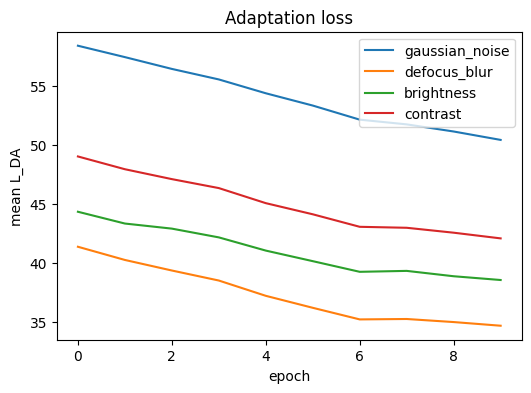

In [15]:
CFG.sinkhorn_lr = 1e-4
CFG.epochs = 10
SEEDS = [0,1,2]

class CachedDataset(Dataset):
    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]


def run_roda_seed(target_tr, target_te, memory_bank, CFG, seed):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return auroc, history

roda_runs = {}
histories = {}


for c in CFG.corruptions:
    t0 = time.time()
    tr, te = make_test_split(c, CFG)
    tr, te = CachedDataset(tr), CachedDataset(te)
    roda_runs[c], histories[c] = [], []
    for sd in SEEDS:
        print(f"[{c}] seed {sd}")
        a, h = run_roda_seed(tr, te, memory_bank, CFG, sd)
        roda_runs[c].append(a)
        histories[c].append(h)
        print(f"  -> AUROC {a:.4f}")
    print(f"[{c}] done in {time.time()-t0:.0f}s\n")


rows = []
for c in CFG.corruptions:
    m, s = np.mean(roda_runs[c]), np.std(roda_runs[c])
    rows.append({
        "corruption": c,
        "clean": baseline_results["clean"],
        "w/o adapt": baseline_results[c],
        "RoDA mean":m,
        "RoDA std":s,
        "diff":m-baseline_results[c],
    })
results_df = pd.DataFrame(rows).set_index("corruption").round(4)
print(results_df)

plt.figure(figsize=(6,4))
for c in CFG.corruptions:
    plt.plot(np.mean(histories[c], axis=0), label=c)
plt.xlabel("epoch")
plt.ylabel("mean L_DA")
plt.legend()
plt.title("Adaptation loss")
plt.show()

## AUROC Calculation

### AUROC Result

In [16]:
import gc, time
CFG.assignment, CFG.aug_mode = "discrete", "augment"

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
              "metal_nut", "tile", "toothbrush", "transistor", "wood", "zipper"]
RESULTS_EXCEL = "RoDA+Norm_AUROC_Before&After_results.xlsx"


CFG.coreset_ratio = 0.1

def run_category(cat, base_model, CFG):
    CFG.category = cat
    src_loader = DataLoader(SourceDataset(CFG, CFG.root, cat), batch_size=CFG.batch_size,
                            shuffle=False, num_workers=CFG.num_workers)
    bank = build_memory_bank(base_model, src_loader, CFG)

    rows = []
    for c in [None] + list(CFG.corruptions):
        tr, te = make_test_split(c, CFG)
        tr, te = CachedDataset(tr), CachedDataset(te)
        before = evaluate(base_model, make_loader(te, CFG), bank, CFG)
        if c is None:
            rows.append(dict(category=cat, corruption="clean", before=before, after=np.nan, std=np.nan))
            continue
        aurocs = [run_roda_seed(tr, te, bank, CFG, sd)[0] for sd in SEEDS]
        rows.append(dict(category=cat, corruption=c, before=before,
                         after=np.mean(aurocs), std=np.std(aurocs)))
        print(f"  {cat:12s} {c:15s} before {before:.4f}  after {np.mean(aurocs):.4f}")
        del tr, te
    del bank
    gc.collect(); torch.cuda.empty_cache()
    return rows


base_model = FeatureExtractor(CFG).to(CFG.device)
existing_results = pd.read_excel(RESULTS_EXCEL) if os.path.exists(RESULTS_EXCEL) else pd.DataFrame()
done = set(existing_results["category"]) if not existing_results.empty else set()

for cat in CATEGORIES:
    if cat in done:
        continue
    t0 = time.time()
    print(f"[{cat}]")
    rows = run_category(cat, base_model, CFG)
    existing_results = pd.concat([existing_results, pd.DataFrame(rows)], ignore_index=True)
    existing_results.to_excel(RESULTS_EXCEL, index=False)
    print(f"[{cat}] done in {(time.time()-t0)/60:.1f} min\n")


df = pd.read_excel(RESULTS_EXCEL)
corr = df[df.corruption != "clean"]
print("Per category (after adaptation):")
print(corr.pivot(index="category", columns="corruption", values="after").round(4))
summary = corr.groupby("corruption")[["before", "after"]].mean()
summary.loc["mean"] = summary.mean()
summary["clean (mean)"] = df[df.corruption == "clean"]["before"].mean()
print("\nAverage over categories:")
print((summary * 1).round(4))

CFG.category = "bottle"

[bottle]
Source patches: 163856, memory bank size N_M: 16385
  epoch 1/10  loss 30.0661
  epoch 2/10  loss 29.3029
  epoch 3/10  loss 28.7001
  epoch 4/10  loss 28.3162
  epoch 5/10  loss 27.7540
  epoch 6/10  loss 27.2500
  epoch 7/10  loss 26.5371
  epoch 8/10  loss 26.2377
  epoch 9/10  loss 26.2352
  epoch 10/10  loss 25.6862
  epoch 1/10  loss 29.7035
  epoch 2/10  loss 29.1749
  epoch 3/10  loss 28.6780
  epoch 4/10  loss 28.2253
  epoch 5/10  loss 27.7894
  epoch 6/10  loss 27.3940
  epoch 7/10  loss 26.6391
  epoch 8/10  loss 26.5186
  epoch 9/10  loss 25.9924
  epoch 10/10  loss 25.8813
  epoch 1/10  loss 29.6659
  epoch 2/10  loss 29.4547
  epoch 3/10  loss 29.0649
  epoch 4/10  loss 28.4815
  epoch 5/10  loss 27.6971
  epoch 6/10  loss 26.9679
  epoch 7/10  loss 26.6495
  epoch 8/10  loss 26.4193
  epoch 9/10  loss 26.0986
  epoch 10/10  loss 25.6458
  bottle       gaussian_noise  before 0.8566  after 0.8889
  epoch 1/10  loss 21.2930
  epoch 2/10  loss 20.5496
  epoch 3/10 

In [17]:
def get_threshold_at_fpr(normal_scores, target_fpr=0.05):
    normal_scores = np.asarray(normal_scores).reshape(-1)
    threshold = np.quantile(normal_scores, 1.0 - target_fpr)
    return threshold


def compute_recall(scores, labels, threshold):
    scores = np.asarray(scores).reshape(-1)
    labels = np.asarray(labels).reshape(-1)

    preds = (scores >= threshold).astype(int)
    tp = np.sum((preds == 1) & (labels == 1))
    fn = np.sum((preds == 0) & (labels == 1))

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return recall, tp, fn


def evaluate_recall(model, test_loader, memory_bank, CFG, normal_loader=None, target_fpr=0.05):
    test_scores, test_labels = score_images(
        model, test_loader, memory_bank, CFG.device
    )

    if normal_loader is not None:
        normal_scores, _ = score_images(
            model, normal_loader, memory_bank, CFG.device
        )
    else:
        normal_scores = test_scores[test_labels == 0]

    threshold = get_threshold_at_fpr(normal_scores, target_fpr)
    recall, tp, fn = compute_recall(test_scores, test_labels, threshold)

    return {
        "recall": recall,
        "threshold": threshold,
        "target_fpr": target_fpr,
        "true_positives": int(tp),
        "false_negatives": int(fn),
        "defective_images": int(tp + fn),
    }

In [18]:
def recall_before_roda(base_model, test_subset, memory_bank, CFG, target_fpr=0.05):
    return evaluate_recall(base_model, make_loader(test_subset, CFG), memory_bank, CFG,
                           normal_loader=None, target_fpr=target_fpr)

def run_roda_seed_with_recall(target_tr, target_te, memory_bank, CFG, seed, target_fpr=0.05):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    res = evaluate_recall(model_a, make_loader(target_te, CFG), memory_bank, CFG,
                          normal_loader=None, target_fpr=target_fpr)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return res, history

### AUROC plot

Source patches: 163856, memory bank size N_M: 16385
  epoch 1/10  loss 30.0661
  epoch 2/10  loss 29.3029
  epoch 3/10  loss 28.7002
  epoch 4/10  loss 28.3162
  epoch 5/10  loss 27.7532
  epoch 6/10  loss 27.2499
  epoch 7/10  loss 26.5371
  epoch 8/10  loss 26.2377
  epoch 9/10  loss 26.2352
  epoch 10/10  loss 25.6870
  epoch 1/10  loss 21.2930
  epoch 2/10  loss 20.5496
  epoch 3/10  loss 19.8270
  epoch 4/10  loss 19.6624
  epoch 5/10  loss 18.9885
  epoch 6/10  loss 18.6710
  epoch 7/10  loss 17.7730
  epoch 8/10  loss 17.8241
  epoch 9/10  loss 18.1155
  epoch 10/10  loss 17.8171
  epoch 1/10  loss 22.8887
  epoch 2/10  loss 22.1097
  epoch 3/10  loss 21.5705
  epoch 4/10  loss 21.4504
  epoch 5/10  loss 20.9247
  epoch 6/10  loss 20.7024
  epoch 7/10  loss 19.8094
  epoch 8/10  loss 19.8154
  epoch 9/10  loss 20.0300
  epoch 10/10  loss 19.7787
  epoch 1/10  loss 25.1885
  epoch 2/10  loss 24.4302
  epoch 3/10  loss 23.8155
  epoch 4/10  loss 23.5833
  epoch 5/10  loss 22.9466


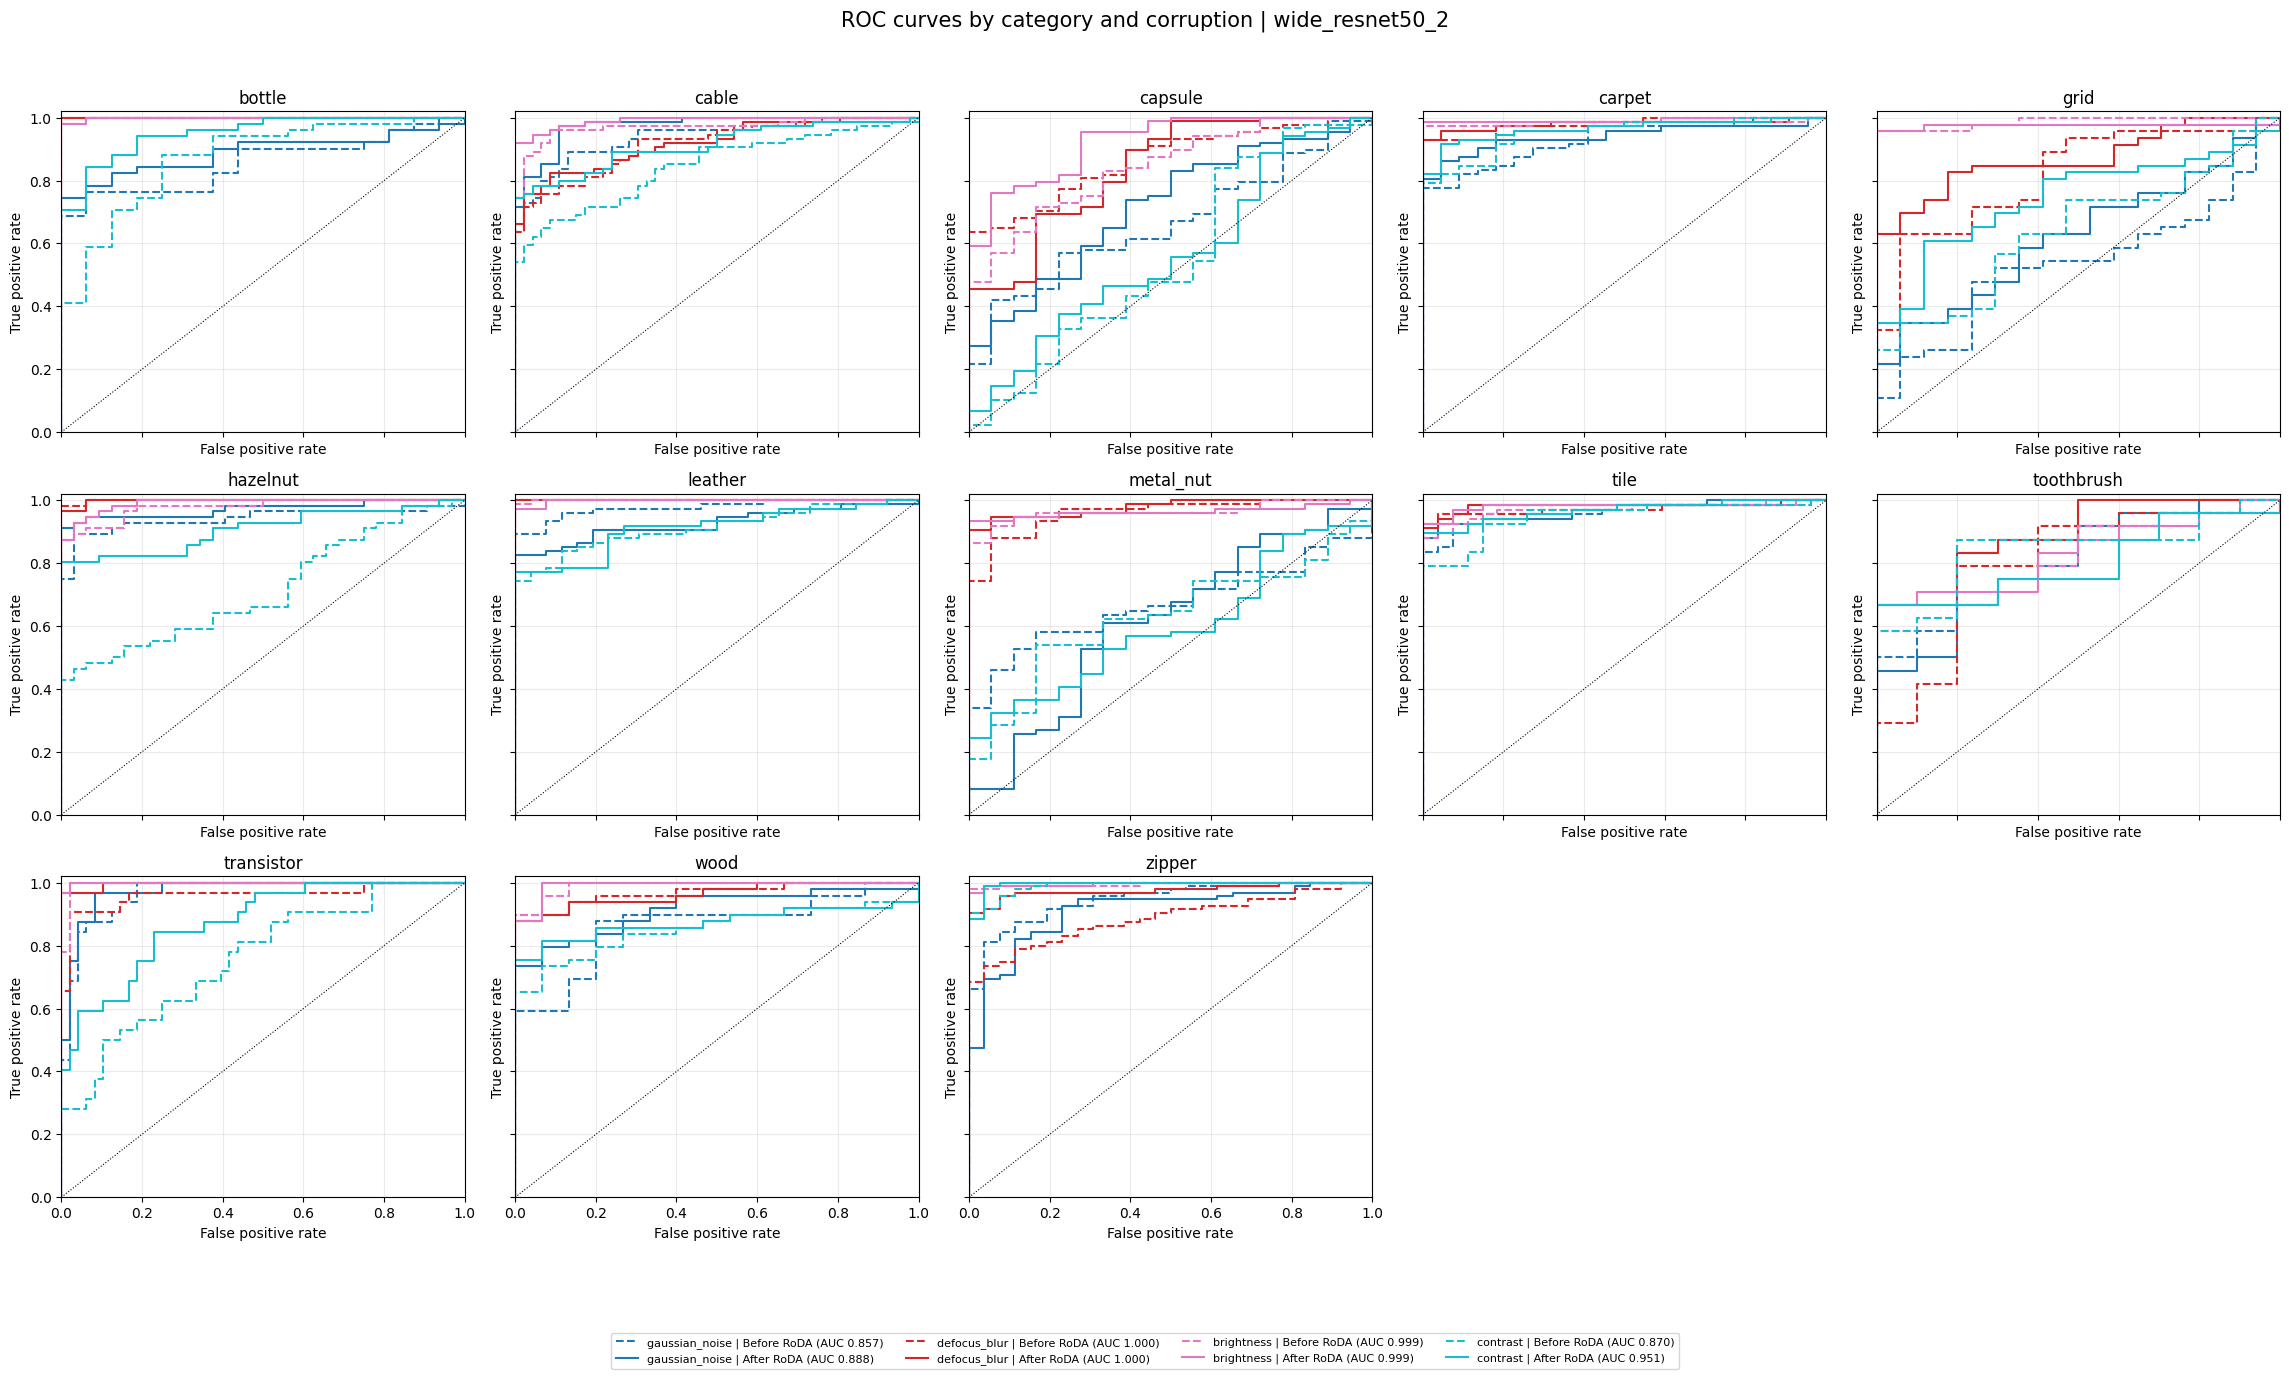

In [25]:
from sklearn.metrics import roc_curve, roc_auc_score

roc_store = {}
fig, axes = plt.subplots(3, 5, figsize=(23, 14), sharex=True, sharey=True)
axes = axes.ravel()
colors = plt.cm.tab10(np.linspace(0, 1, len(CFG.corruptions)))

for ax, category in zip(axes, CATEGORIES):
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        src_loader = DataLoader(
            SourceDataset(CFG, CFG.root, category),
            batch_size=CFG.batch_size,
            shuffle=False,
            num_workers=CFG.num_workers,
        )
        bank = build_memory_bank(base_model, src_loader, CFG)

        for color, corruption in zip(colors, CFG.corruptions):
            tr, te = make_test_split(corruption, CFG)
            tr, te = CachedDataset(tr), CachedDataset(te)
            test_loader = make_loader(te, CFG)

            scores_before, labels = score_images(
                base_model, test_loader, bank, CFG.device
            )

            seed = SEEDS[0]
            torch.manual_seed(seed)
            random.seed(seed)
            np.random.seed(seed)

            model_a, bn_params = make_adapt_model(CFG)
            adapt(model_a, bn_params, tr, bank, CFG)
            scores_after, _ = score_images(
                model_a, test_loader, bank, CFG.device
            )

            for scores, method, linestyle in [
                (scores_before, "Before RoDA", "--"),
                (scores_after, "After RoDA", "-"),
            ]:
                fpr, tpr, _ = roc_curve(labels, scores)
                auc = roc_auc_score(labels, scores)
                ax.plot(
                    fpr, tpr, color=color, linestyle=linestyle, linewidth=1.5,
                    label=f"{corruption} | {method} (AUC {auc:.3f})",
                )

            roc_store[f"{category}_{corruption}_labels"] = labels
            roc_store[f"{category}_{corruption}_before"] = scores_before
            roc_store[f"{category}_{corruption}_after"] = scores_after

            del model_a, bn_params, tr, te, test_loader
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        ax.plot([0, 1], [0, 1], "k:", linewidth=0.8)
        ax.set_title(category)
        ax.grid(alpha=0.25)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        del bank

for ax in axes[len(CATEGORIES):]:
    ax.set_visible(False)

for ax in axes[:len(CATEGORIES)]:
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")

handles, labels_for_legend = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels_for_legend, loc="lower center",
    ncol=4, fontsize=8, bbox_to_anchor=(0.5, 0.005),
)
fig.suptitle(
    f"ROC curves by category and corruption | {CFG.backbone_name}",
    fontsize=15,
)
fig.tight_layout(rect=[0, 0.09, 1, 0.96])
plt.show()

np.savez("roda_normalization_roc_curves.npz", **roc_store)

## Recall Calculation

In [26]:
import io
from contextlib import redirect_stdout

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
              "metal_nut","tile", "toothbrush", "transistor", "wood", "zipper"]
SEEDS = [0, 1, 2]
TARGET_FPR = 0.075
RECALL_EXCEL = "RoDA+Norm_Recall_Before&After_results.xlsx"
all_results = []

base_model = FeatureExtractor(CFG).to(CFG.device)

for category in CATEGORIES:
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        src = DataLoader(SourceDataset(CFG, CFG.root, category), batch_size=CFG.batch_size,
                         shuffle=False, num_workers=CFG.num_workers)
        bank = build_memory_bank(base_model, src, CFG)

        for corruption in CFG.corruptions:
            tr, te = make_test_split(corruption, CFG)
            tr, te = CachedDataset(tr), CachedDataset(te)

            before = recall_before_roda(base_model, te, bank, CFG, TARGET_FPR)
            before.update(category=category, corruption=corruption, model="before_roda")
            all_results.append(before)

            recalls = []
            for seed in SEEDS:
                with redirect_stdout(io.StringIO()):
                    res, _ = run_roda_seed_with_recall(tr, te, bank, CFG, seed, TARGET_FPR)
                recalls.append(res["recall"])
            all_results.append(dict(category=category, corruption=corruption, model="after_roda",
                                    recall=float(np.mean(recalls)), recall_std=float(np.std(recalls)),
                                    target_fpr=TARGET_FPR))
            print(f"{category:12s} | {corruption:15s} | "
                  f"before {before['recall']:.4f} | after {np.mean(recalls):.4f}")

        del bank
        torch.cuda.empty_cache()
    pd.DataFrame(all_results).to_excel(RECALL_EXCEL, index=False)

recall_df = pd.DataFrame(all_results)
recall_pivot = recall_df.pivot_table(index=["category", "corruption"],
                                     columns="model", values="recall").reset_index()
recall_pivot["recall_improvement"] = recall_pivot["after_roda"] - recall_pivot["before_roda"]
print(recall_pivot.round(4))
recall_pivot.to_excel("RoDA+Norm_Recall_Before&After_results.xlsx", index=False)

print(CFG.category, CFG.coreset_ratio)

Source patches: 163856, memory bank size N_M: 16385
bottle       | gaussian_noise  | before 0.7647 | after 0.7843
bottle       | defocus_blur    | before 1.0000 | after 1.0000
bottle       | brightness      | before 1.0000 | after 1.0000
bottle       | contrast        | before 0.5882 | after 0.8758
Source patches: 175616, memory bank size N_M: 17561
cable        | gaussian_noise  | before 0.8108 | after 0.8514
cable        | defocus_blur    | before 0.7568 | after 0.8063
cable        | brightness      | before 0.9189 | after 0.9505
cable        | contrast        | before 0.6622 | after 0.7883
Source patches: 171696, memory bank size N_M: 17169
capsule      | gaussian_noise  | before 0.4205 | after 0.3826
capsule      | defocus_blur    | before 0.6591 | after 0.4621
capsule      | brightness      | before 0.6023 | after 0.7689
capsule      | contrast        | before 0.1250 | after 0.1477
Source patches: 219520, memory bank size N_M: 21952
carpet       | gaussian_noise  | before 0.8056 |

### Recall Plot


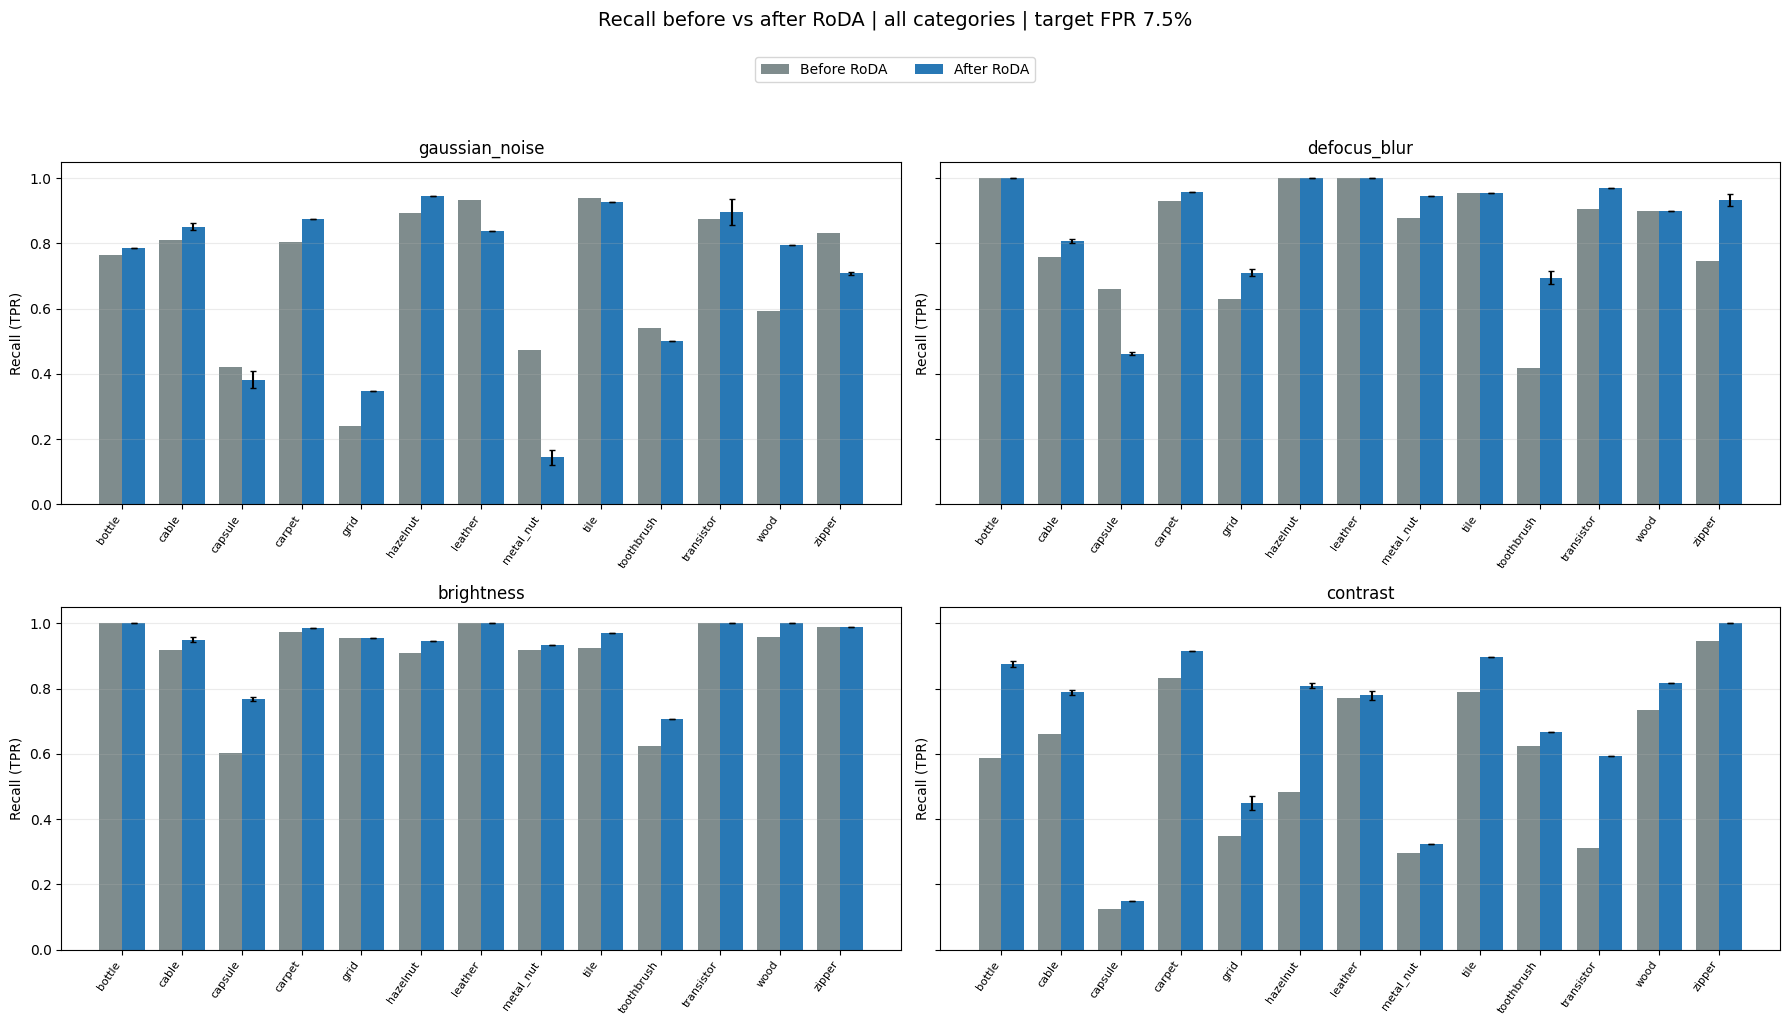

In [27]:
plot_recall_df = pd.DataFrame(all_results)
recall_summary = plot_recall_df.pivot_table(
    index=["category", "corruption"], columns="model", values="recall", aggfunc="mean"
).reset_index()
category_order = [c for c in CATEGORIES if c in set(recall_summary["category"])]
corruption_order = list(CFG.corruptions)
fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharey=True)
axes = axes.ravel()
bar_width = 0.38

for ax, corruption in zip(axes, corruption_order):
    data = (recall_summary[recall_summary["corruption"] == corruption]
            .set_index("category").reindex(category_order))
    x = np.arange(len(category_order))
    before = data["before_roda"].to_numpy(dtype=float)
    after = data["after_roda"].to_numpy(dtype=float)
    after_std = (plot_recall_df[(plot_recall_df["corruption"] == corruption) &
                                (plot_recall_df["model"] == "after_roda")]
                 .set_index("category").reindex(category_order)["recall_std"]
                 .fillna(0).to_numpy(dtype=float))
    ax.bar(x - bar_width/2, before, bar_width, label="Before RoDA", color="#7f8c8d")
    ax.bar(x + bar_width/2, after, bar_width, yerr=after_std, capsize=2,
           label="After RoDA", color="#2878B5")
    ax.set_title(corruption)
    ax.set_xticks(x)
    ax.set_xticklabels(category_order, rotation=55, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Recall (TPR)")
    ax.grid(axis="y", alpha=0.25)

for ax in axes[len(corruption_order):]:
    ax.set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.98))
fig.suptitle(f"Recall before vs after RoDA | all categories | target FPR {TARGET_FPR:.1%}",y=1.02, fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()
